In [1]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END

In [2]:
class State(TypedDict):
    txt : str
    word_count : int
    label: Literal["short", "long"]

In [ ]:
def normalize(state: State)-> dict:
    txt=state["txt"].strip().lower()
    return {"txt": txt}

In [ ]:
def count_words(state:State)-> dict:
    word_count=len(state["txt"].split())
    return {"word_count": word_count}

In [5]:
def find_label(state:State)-> dict:
    label = "short" if state["word_count"]<5 else "long"
    return {"label":label}

In [6]:
builder = StateGraph(State)

builder.add_node("normalize", normalize)
builder.add_node("count_words", count_words)
builder.add_node("find_label", find_label)
builder.add_edge(START, "normalize")
builder.add_edge("normalize", "count_words")
builder.add_edge("count_words", "find_label")
builder.add_edge("find_label", END)

graph = builder.compile()

In [7]:
res = graph.invoke({"txt":"   abuW      ", "word_count":0, "label":"short"})
print(res)

{'txt': ['abuw'], 'word_count': 1, 'label': 'short'}


In [8]:
res = graph.invoke({"txt":"   abuW ewde sdxs dscd dcvd dvdv    ", "word_count":0, "label":"short"})
print(res)

{'txt': ['abuw', 'ewde', 'sdxs', 'dscd', 'dcvd', 'dvdv'], 'word_count': 6, 'label': 'long'}


In [9]:
res = graph.invoke({"txt":" xwWW  abuW ewde     ", "word_count":0, "label":"short"})
print(res)

{'txt': ['xwww', 'abuw', 'ewde'], 'word_count': 3, 'label': 'short'}


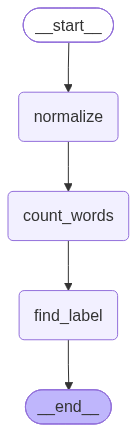

In [10]:
from IPython.display import Image, display 

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Error in graph making", e)

In [11]:
builder = StateGraph(State)

builder.add_node(normalize)
builder.add_node(count_words)
builder.add_node(find_label)
builder.add_edge(START, "normalize")
builder.add_edge("normalize", "count_words")
builder.add_edge("count_words", "find_label")
builder.add_edge("find_label", "not_a_node")

graph2 = builder.compile()

ValueError: Found edge ending at unknown node `not_a_node`